# DSA Assignment 1 — Q2: JL for linear regression
**Snehil Modi (2024558), Vasu Mehta (2024601)**

All randomness comes from `SEED = 2024558` via numpy `default_rng`. Every least-squares problem uses `numpy.linalg.lstsq`. CountSketch S is never stored densely: rows of D are added with sign σ(i) into row h(i) of SD with `numpy.add.at`.

In [1]:
import time, json, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99

SEED = 2024558            # master seed: every random number below is derived from it
os.makedirs("figs", exist_ok=True)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "font.size": 10})
MS = [50, 100, 200, 500, 1000, 2000, 5000]
REPS = 5

## Data matrix D and response y

In [2]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
X = kdd.data.copy()
cat_cols = ["protocol_type", "service", "flag"]
for c in cat_cols:                                   # bytes -> str for readable column names
    X[c] = X[c].apply(lambda v: v.decode() if isinstance(v, bytes) else v)
num_cols = [c for c in X.columns if c not in cat_cols]

# (i) one-hot encode the 3 text features, convert the other 38 to float
Df = pd.concat([X[num_cols].astype(float),
                pd.get_dummies(X[cat_cols], prefix=cat_cols, dtype=float)], axis=1)
d_before = Df.shape[1]
# (ii) drop every column that is constant on all rows
const_cols = list(Df.columns[Df.nunique() <= 1])
Df = Df.drop(columns=const_cols)
# (iii) min-max rescale every column to [0, 1]
Df = (Df - Df.min()) / (Df.max() - Df.min())

D = Df.to_numpy(dtype=np.float64)
n, d = D.shape
print(f"columns after one-hot: {d_before}; constant columns dropped: {const_cols}")
print(f"n = {n}, d = {d}, min = {D.min()}, max = {D.max()}")

y = (kdd.target != b'normal.').to_numpy(dtype=float)
print(f"attacks: {int(y.sum())} of {n} ({y.mean():.3f})")
rankD = np.linalg.matrix_rank(D)
print("rank(D) =", rankD)


columns after one-hot: 118; constant columns dropped: ['num_outbound_cmds', 'is_host_login']
n = 494021, d = 116, min = 0.0, max = 1.0
attacks: 396743 of 494021 (0.803)


rank(D) = 113


In [3]:
def loss(X, y, a):
    r = X @ a - y
    return float(r @ r)

def countsketch(X, y, m, rng):
    """Return SX and Sy for a CountSketch S (m x n) without materialising S."""
    nn = X.shape[0]
    h = rng.integers(0, m, size=nn)                 # bucket h(i) uniform in {0..m-1}
    sg = rng.choice(np.array([-1.0, 1.0]), size=nn) # sign sigma(i) uniform in {-1,+1}
    SX = np.zeros((m, X.shape[1])); Sy = np.zeros(m)
    np.add.at(SX, h, sg[:, None] * X)
    np.add.at(Sy, h, sg * y)
    return SX, Sy


## (a) Full least squares

In [4]:
t0 = time.perf_counter()
b, *_ = np.linalg.lstsq(D, y, rcond=None)
time_b = time.perf_counter() - t0
loss_b = loss(D, y, b)
print(f"Loss(D, y, b) = {loss_b:.4f}")
print(f"time to compute b = {time_b:.3f} s")


Loss(D, y, b) = 2949.7888
time to compute b = 7.178 s


## (b), (c) CountSketch for m ∈ {50, …, 5000}, 5 runs each
Timed part (c): drawing S (h and σ), forming SD and Sy, and solving for ã.

In [5]:
rows = []
for m in MS:
    for r in range(REPS):
        rng = np.random.default_rng([SEED, 1, m, r])
        t0 = time.perf_counter()
        SD, Sy = countsketch(D, y, m, rng)
        a_t, *_ = np.linalg.lstsq(SD, Sy, rcond=None)
        t_run = time.perf_counter() - t0
        L = loss(D, y, a_t)
        rows.append(dict(m=m, run=r + 1, loss=L, ratio=L / loss_b, sketched_loss=loss(SD, Sy, a_t),
                         rank_SD=int(np.linalg.matrix_rank(SD)), time=t_run))
        print(f"m={m:5d} run={r+1}  Loss={L:14.4f}  ratio={L/loss_b:12.4f}  sketched={rows[-1]['sketched_loss']:12.4f}  t={t_run:.3f}s")
runs = pd.DataFrame(rows)
summary = runs.groupby("m").agg(mean_loss=("loss", "mean"), mean_ratio=("ratio", "mean"),
                                min_ratio=("ratio", "min"), max_ratio=("ratio", "max"),
                                mean_sketched_loss=("sketched_loss", "mean"),
                                min_rank_SD=("rank_SD", "min"), mean_time=("time", "mean")).reset_index()
summary["time / time_b"] = summary["mean_time"] / time_b
pd.set_option("display.float_format", "{:.4f}".format)
summary


m=   50 run=1  Loss=     8654.9410  ratio=      2.9341  sketched=      0.0000  t=2.242s


m=   50 run=2  Loss=    12733.5425  ratio=      4.3168  sketched=      0.0000  t=1.603s


m=   50 run=3  Loss=    19654.0470  ratio=      6.6629  sketched=      0.0000  t=1.355s


m=   50 run=4  Loss=    15858.1090  ratio=      5.3760  sketched=      0.0000  t=1.940s


m=   50 run=5  Loss=    15290.7364  ratio=      5.1837  sketched=      0.0000  t=1.007s


m=  100 run=1  Loss=    46607.8230  ratio=     15.8004  sketched=      0.0000  t=1.073s


... (26 outputs left out)

m= 5000 run=3  Loss=     3023.1226  ratio=      1.0249  sketched=   2917.3089  t=0.866s


m= 5000 run=4  Loss=     3016.7284  ratio=      1.0227  sketched=   2907.0362  t=1.124s


m= 5000 run=5  Loss=     3016.2235  ratio=      1.0225  sketched=   2880.5471  t=1.577s


,m,mean_loss,mean_ratio,min_ratio,max_ratio,mean_sketched_loss,min_rank_SD,mean_time,time / time_b
0,50,14438.2752,4.8947,2.9341,6.6629,0.0000,50,1.6294,0.2270
1,100,36948.6056,12.5258,7.8960,15.8004,0.0000,100,1.0000,0.1393
2,200,7300.9175,2.4751,2.1044,2.7791,1063.2659,113,1.4039,0.1956
3,500,3826.4009,1.2972,1.2254,1.3690,2334.9185,113,1.1424,0.1592
4,1000,3284.1746,1.1134,1.0910,1.1500,2593.2906,113,1.2961,0.1806
5,2000,3130.9460,1.0614,1.0560,1.0690,2740.8090,113,1.3214,0.1841
6,5000,3013.9177,1.0217,1.0147,1.0249,2898.2333,113,1.0440,0.1454


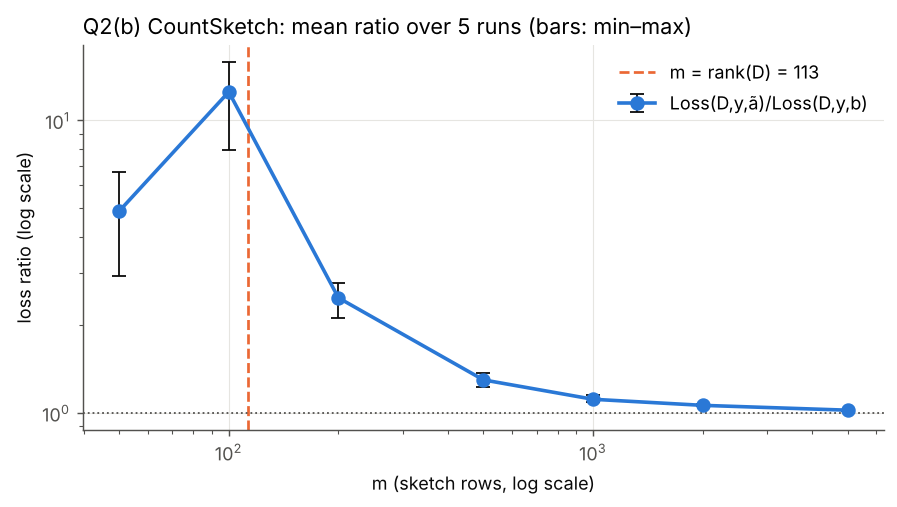

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
mean = summary["mean_ratio"]
ax.errorbar(summary["m"], mean, yerr=[mean - summary["min_ratio"], summary["max_ratio"] - mean],
            fmt="-o", color=BLUE, lw=2, ms=7, capsize=4, ecolor=INK, elinewidth=1, label="Loss(D,y,ã)/Loss(D,y,b)")
ax.axvline(rankD, color=ORANGE, lw=1.5, ls="--", label=f"m = rank(D) = {rankD}")
ax.axhline(1, color=MUTED, lw=1, ls=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("m (sketch rows, log scale)"); ax.set_ylabel("loss ratio (log scale)")
ax.set_title("Q2(b) CountSketch: mean ratio over 5 runs (bars: min–max)", loc="left")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figs/q2_b_ratio.png", dpi=200); plt.show()


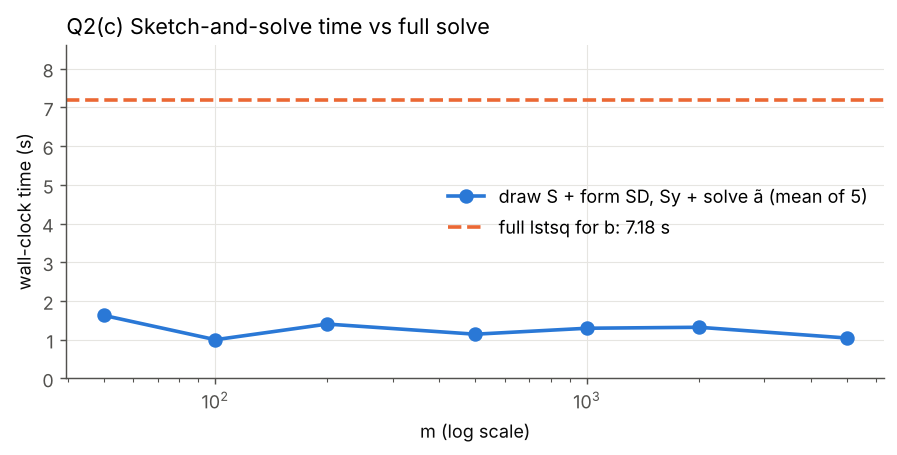

In [7]:
# (c) timing comparison
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(summary["m"], summary["mean_time"], "-o", color=BLUE, lw=2, ms=7, label="draw S + form SD, Sy + solve ã (mean of 5)")
ax.axhline(time_b, color=ORANGE, lw=2, ls="--", label=f"full lstsq for b: {time_b:.2f} s")
ax.set_xscale("log"); ax.set_xlabel("m (log scale)"); ax.set_ylabel("wall-clock time (s)")
ax.set_ylim(0, max(time_b, summary["mean_time"].max()) * 1.2)
ax.set_title("Q2(c) Sketch-and-solve time vs full solve", loc="left"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figs/q2_c_time.png", dpi=200); plt.show()


## (d) Norm preservation of the residual v = Db − y

In [8]:
v = D @ b - y
vv = float(v @ v)
dres = {}
for m in [50, 500, 5000]:
    vals = []
    for t in range(100):
        rng = np.random.default_rng([SEED, 2, m, t])
        h = rng.integers(0, m, size=n); sg = rng.choice(np.array([-1.0, 1.0]), size=n)
        Sv = np.zeros(m); np.add.at(Sv, h, sg * v)
        vals.append(float(Sv @ Sv) / vv)
    dres[m] = np.array(vals)
d_tab = pd.DataFrame({"m": list(dres), "mean": [x.mean() for x in dres.values()],
                      "std": [x.std(ddof=1) for x in dres.values()],
                      "min": [x.min() for x in dres.values()], "max": [x.max() for x in dres.values()],
                      "sqrt(2/m) (theory)": [np.sqrt(2 / m) for m in dres]})
d_tab


,m,mean,std,min,max,sqrt(2/m) (theory)
0,50,1.0188,0.1857,0.5549,1.4435,0.2000
1,500,0.9919,0.0646,0.8626,1.1787,0.0632
2,5000,0.9970,0.0204,0.9527,1.0410,0.0200


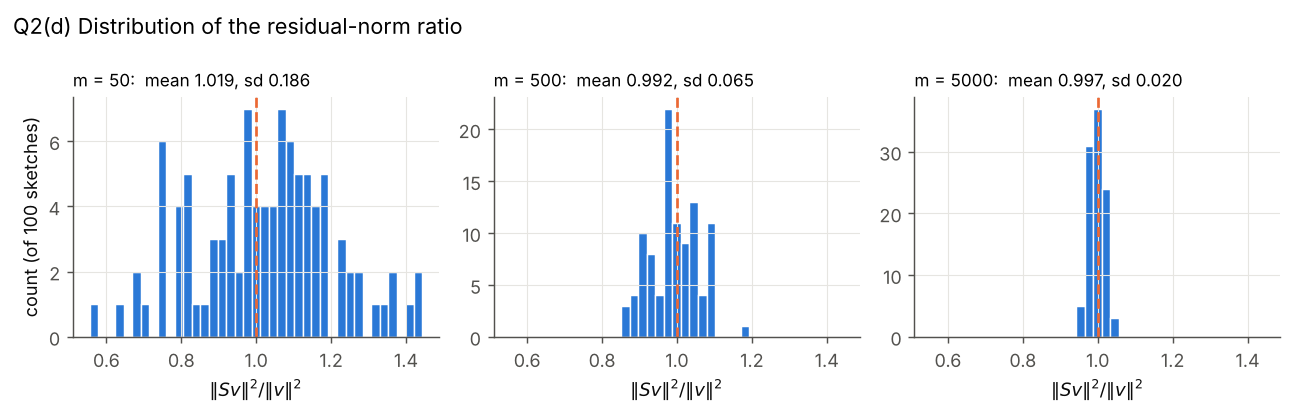

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharex=True)
lo = min(x.min() for x in dres.values()); hi = max(x.max() for x in dres.values())
bins = np.linspace(lo, hi, 40)
for ax, (m, x) in zip(axes, dres.items()):
    ax.hist(x, bins=bins, color=BLUE, edgecolor="white", linewidth=0.8)
    ax.axvline(1, color=ORANGE, lw=1.5, ls="--")
    ax.set_title(f"m = {m}:  mean {x.mean():.3f}, sd {x.std(ddof=1):.3f}", loc="left", fontsize=9.5)
    ax.set_xlabel(r"$\|Sv\|^2/\|v\|^2$")
axes[0].set_ylabel("count (of 100 sketches)")
fig.suptitle("Q2(d) Distribution of the residual-norm ratio", x=0.01, ha="left")
fig.tight_layout(); fig.savefig("figs/q2_d_hist.png", dpi=200); plt.show()


## (e) CountSketch vs dense Gaussian sketch on a 50,000-row subset, m = 500

In [10]:
rng_sub = np.random.default_rng([SEED, 5])
idx = rng_sub.choice(n, size=50_000, replace=False)            # drawn once, fixed seed
Dp, yp = D[idx], y[idx]
bp_, *_ = np.linalg.lstsq(Dp, yp, rcond=None)
loss_bp = loss(Dp, yp, bp_)
print(f"Loss(D', y', b') = {loss_bp:.4f}")
m = 500; e_rows = []
for r in range(REPS):
    # (i) CountSketch
    rng = np.random.default_rng([SEED, 6, r])
    t0 = time.perf_counter(); SDp, Syp = countsketch(Dp, yp, m, rng); t_cs = time.perf_counter() - t0
    a_cs, *_ = np.linalg.lstsq(SDp, Syp, rcond=None)
    # (ii) dense Gaussian N(0, 1/m)
    rng = np.random.default_rng([SEED, 7, r])
    t0 = time.perf_counter()
    S = rng.normal(0.0, 1.0 / np.sqrt(m), size=(m, Dp.shape[0]))
    SDg, Syg = S @ Dp, S @ yp
    t_g = time.perf_counter() - t0
    a_g, *_ = np.linalg.lstsq(SDg, Syg, rcond=None)
    e_rows += [dict(sketch="CountSketch", run=r + 1, time=t_cs, ratio=loss(Dp, yp, a_cs) / loss_bp),
               dict(sketch="Dense Gaussian", run=r + 1, time=t_g, ratio=loss(Dp, yp, a_g) / loss_bp)]
e_runs = pd.DataFrame(e_rows)
e_tab = e_runs.groupby("sketch").agg(mean_time_s=("time", "mean"), mean_ratio=("ratio", "mean"),
                                     min_ratio=("ratio", "min"), max_ratio=("ratio", "max")).reset_index()
e_tab


Loss(D', y', b') = 301.5687


,sketch,mean_time_s,mean_ratio,min_ratio,max_ratio
0,CountSketch,0.0796,1.2623,1.2009,1.3157
1,Dense Gaussian,0.9063,1.2787,1.2500,1.3203


In [11]:
out = dict(n=n, d=d, const_cols=const_cols, rankD=int(rankD), attack_frac=float(y.mean()),
           loss_b=loss_b, time_b=time_b, runs=runs.to_dict("records"), summary=summary.to_dict("records"),
           d_tab=d_tab.to_dict("records"), loss_bp=loss_bp, e_runs=e_runs.to_dict("records"),
           e_tab=e_tab.to_dict("records"))
json.dump(out, open("results_q2.json", "w"), indent=1)
